# Primera Version Completa del GA con Evaluacion Paralela Real — Arrhythmia

**Replica de `04_ga_full_version.ipynb` (WDBC) sobre el dataset Arrhythmia** (`OpenML 'arrhythmia' v1`).

**Motivacion:** los resultados del mes 3 se basaban en un unico dataset (WDBC, `D=30`),
relativamente pequeno y sencillo. Este notebook incorpora **Arrhythmia** (`D=279`)
para validar el GA-wrapper sobre Spark RDD en mayor dimensionalidad, como se anticipa en
`mes3.md` §8 (siguiente paso) y `diseño_GA.md` §1/§6.

**Objetivo (Hito 6, extension a Arrhythmia):** integrar el ciclo evolutivo completo del GA
(seleccion, cruce, mutacion, elitismo) con la evaluacion paralela real de fitness usando
Gaussian Naive Bayes (GNB) y validacion cruzada de 5 pliegues sobre Spark RDD.

**Observaciones a recoger:**
1. **Convergencia**: evolucion del mejor fitness generacion tras generacion.
2. **Evolucion del fitness**: mejor, medio y peor por generacion.
3. **Numero de caracteristicas seleccionadas**: presion selectiva hacia subconjuntos parsimoniosos.
4. **Tiempos**: duracion de la fase de evaluacion (Workers) vs. operadores geneticos (Driver) por generacion.

**Coherencia con el diseno del TFM:**
- Parametros del GA: tomados de la tabla de `diseño_GA.md` §6 (columna **Arrhythmia**).
- Clasificador: GNB por su velocidad y ausencia de hiperparametros (§5.1).
- Patron de paralelizacion: `sc.parallelize -> map -> collect` con broadcast del dataset (`arquitectura_spark_rdd_ga.md` §2).
- Criterio de parada dual: $G_{max}$ generaciones **o** $\Delta\text{fitness} < 0.001$ en las ultimas $N_{stop}=15$ generaciones.

**Cobertura tambien del Hito 7** (documentacion): la seccion final captura configuracion de Spark, hardware y parametros del GA en un bloque reproducible, y exporta todas las series temporales a CSV.

---
## 1. Setup: Spark Session e Imports

In [13]:
import sys
sys.path.insert(0, '../src')

import warnings
# Arrhythmia es multiclase con clases muy pequenas (2-5 muestras): con
# StratifiedKFold(cv) algun fold puede no contener esas clases. El aviso es
# inofensivo (no afecta el calculo) pero se repite miles de veces, asi que
# se silencia para mantener legible la salida del ciclo evolutivo.
warnings.filterwarnings('ignore', message='The least populated class in y')

from spark_config import crear_sesion_spark, mostrar_info_spark, parar_spark
from datasets_loader import cargar_dataset
import numpy as np
import time
from datetime import datetime
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

print(f"Notebook iniciado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Notebook iniciado: 2026-06-13 12:09:59


In [14]:
SPARK_APP_NAME = "TFM_GA_Full_Arrhythmia"
SPARK_MASTER = "local[*]"
SPARK_DRIVER_MEM = "4g"
SPARK_EXECUTOR_MEM = "4g"
SPARK_UI_PORT = 4040

spark = crear_sesion_spark(
    app_name=SPARK_APP_NAME,
    master=SPARK_MASTER,
    driver_memory=SPARK_DRIVER_MEM,
    executor_memory=SPARK_EXECUTOR_MEM,
    ui_port=SPARK_UI_PORT,
    verbose=False
)

sc = spark.sparkContext
mostrar_info_spark(spark, ui_port=SPARK_UI_PORT)

# Set de NUM_CORES para paralelismo en Spark
NUM_CORES = sc.defaultParallelism
print(f"\nCores disponibles para paralelismo: {NUM_CORES}")

🔥 INFORMACIÓN DE SPARK SESSION
✓ App Name: TFM_GA_Full_Arrhythmia
✓ Master: local[*]
✓ Spark Version: 3.5.0
✓ Python Version: 3.9
✓ Default Parallelism: 8
✓ Default Min Partitions: 2

🌐 SPARK WEB UI
📊 Accede en tu navegador a:
   👉 http://localhost:4040

   Opciones disponibles:
   - Jobs: Ver trabajos en ejecución/completados
   - Stages: Ver stages de cada job
   - Storage: Ver RDDs cacheados
   - Environment: Configuración de Spark
   - Executors: Estado de ejecutores


Cores disponibles para paralelismo: 8


---
## 2. Carga del Dataset Arrhythmia

El dataset **Arrhythmia** (UCI / OpenML) contiene **279 caracteristicas** clinicas extraidas de electrocardiogramas (mediciones, intervalos y amplitudes) y una variable objetivo **multiclase** (presencia y tipo de arritmia). Es sustancialmente mas grande y dificil que WDBC: mayor dimensionalidad (`D=279` vs. 30), menos muestras (~452), **valores faltantes** y **clases muy desbalanceadas**. Esto pone a prueba con seriedad tanto el GA como la arquitectura Spark, como se anticipa en `mes3_resultados.md` §4.3.

A diferencia de WDBC (disponible directamente en `sklearn.datasets.load_breast_cancer`),
Arrhythmia se descarga desde **OpenML** mediante `fetch_openml`. La logica de carga y
el preprocesado minimo estan centralizados en `src/datasets_loader.py` para garantizar que
los tres datasets (WDBC, Arrhythmia, Gisette) comparten el mismo punto de entrada.

> **Preprocesado (Arrhythmia):** OpenML codifica los valores ausentes como `NaN`. Como `GaussianNB` no admite `NaN`, `datasets_loader.cargar_arrhythmia()` los **imputa por la media de cada columna** (`SimpleImputer`), opcion conservadora y sin hiperparametros. El target multiclase se mantiene como entero (GNB es multiclase nativo).

> **Nota sobre el rango de fitness y los folds de CV (importante para interpretar resultados):**
> Arrhythmia se trata aqui como problema **multiclase con 13 clases**, muy desbalanceado: la clase
> mayoritaria (ritmo normal) supone ~54% de las muestras y varias clases tienen solo 2-5 ejemplos.
> En este escenario, `GaussianNB` (que asume independencia y normalidad de las 279 features clinicas)
> rinde de forma genuinamente baja: la accuracy 5-fold con **todas** las features ronda ~0.16. Por
> tanto, el **fitness** del GA (`0.9*acc - 0.1*|S|/D`) se movera en valores bajos (~0.1-0.2). **Esto es
> un resultado real y correcto, no un fallo**: el GA sigue mejorando sobre el baseline pobre y reduciendo
> dimensionalidad. De hecho ilustra una limitacion conocida de GNB en alta dimensionalidad multiclase,
> que es justamente lo que motiva el clasificador secundario de validacion (LinearSVC, `diseño_GA.md` §5.2).
>
> Por el desbalanceo extremo, se usa **`CV_FOLDS = 3`** (no 5): con 5 folds, las clases de 2-5 muestras
> no caben en todos los pliegues y `StratifiedKFold` lo advierte. Con 3 folds el reparto es mas estable.
> El aviso residual de scikit-learn se silencia en la seccion 1 para no saturar la salida.

In [15]:
# Carga via OpenML (cacheada en ~/scikit_learn_data tras la 1a descarga)
X, y, feature_names, ds_info = cargar_dataset("arrhythmia")
X = np.ascontiguousarray(X)          # contiguo para indexado rapido en workers
feature_names = list(feature_names)
D = X.shape[1]                       # numero de caracteristicas = longitud del cromosoma

print(f"Dataset: {ds_info['nombre']}  ({ds_info['fuente']})")
print(f"Muestras: {X.shape[0]}")
print(f"Caracteristicas (D): {D}")
print(f"Clases: {ds_info['n_clases']}  ->  {dict(zip(*np.unique(y, return_counts=True)))}")
print(f"Preprocesado: {ds_info['preprocesado']}")
if ds_info.get('n_valores_imputados'):
    print(f"Valores faltantes imputados: {ds_info['n_valores_imputados']}")
print(f"\nPrimeras 5 caracteristicas: {feature_names[:5]}")

# Verificacion: la longitud del cromosoma debe coincidir con el diseno (D=279)
assert D == 279, f"D={D} no coincide con el valor de diseno (279) para Arrhythmia"
print(f"\nD={D} coincide con diseño_GA.md §6 (columna Arrhythmia).")

Dataset: Arrhythmia  (OpenML 'arrhythmia' v1)
Muestras: 452
Caracteristicas (D): 279
Clases: 13  ->  {1: 245, 2: 44, 3: 15, 4: 15, 5: 13, 6: 25, 7: 3, 8: 2, 9: 9, 10: 50, 14: 4, 15: 5, 16: 22}
Preprocesado: imputacion por media (SimpleImputer)
Valores faltantes imputados: 408

Primeras 5 caracteristicas: ['age', 'sex', 'height', 'weight', 'QRSduration']

D=279 coincide con diseño_GA.md §6 (columna Arrhythmia).


### 2.1 Nota metodologica: desbalanceo de clases y validacion cruzada estratificada

Al evaluar el fitness sobre Arrhythmia, scikit-learn emite repetidamente el aviso:

```
UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
```

**Causa.** El fitness usa `cross_val_score`, que para clasificacion aplica por defecto
**validacion cruzada estratificada** (`StratifiedKFold`): divide los datos en $k$ pliegues
manteniendo en cada uno la misma proporcion de clases que en el conjunto completo. Para que una
clase aparezca en los $k$ pliegues necesita **al menos $k$ muestras** (una por pliegue).
Arrhythmia es un problema de **13 clases fuertemente desbalanceado**: la clase mayoritaria
(ritmo normal) concentra ~54% de las 452 muestras, mientras que varias clases tienen muy pocos
ejemplos:

| Clase | Muestras | Clase | Muestras |
|:---:|:---:|:---:|:---:|
| 1 (normal) | 245 | 9 | 9 |
| 2 | 44 | 10 | 50 |
| 3 | 15 | 14 | 4 |
| 4 | 15 | 15 | 5 |
| 5 | 13 | 16 | 22 |
| 6 | 25 | **7** | **3** |
| 8 | **2** | | |

La clase 8, con solo **2 muestras**, no puede repartirse en 5 pliegues: queda presente en 2 de
ellos y ausente en los otros 3. scikit-learn lo detecta, **avisa** y continua el calculo (es un
`UserWarning`, no un error).

**Consecuencias.**

1. En los pliegues donde una clase minoritaria no aparece en entrenamiento, el clasificador no
   puede aprenderla ni, por tanto, predecirla.
2. Cuando esas mismas muestras actuan como test, se clasifican necesariamente mal.
3. Esto **degrada y aniade ruido** a la estimacion de accuracy, especialmente para las clases
   diminutas, y contribuye a la baja accuracy global de GNB sobre este dataset (~0.16 con todas
   las features; ver nota en la seccion 2).

**Decisiones adoptadas (documentadas para el TFM).**

- Se mantiene el problema **multiclase original (13 clases)**, por fidelidad al dataset y para no
  introducir decisiones de agrupacion o binarizacion que alterarian la naturaleza del benchmark.
- Se reduce la validacion cruzada a **`CV_FOLDS = 3`** (en lugar de 5): con menos pliegues, el
  requisito de muestras minimas por clase es menos estricto y el reparto estratificado es mas
  estable. Aun asi, la clase 8 (2 muestras) sigue por debajo de 3; el efecto residual es
  inevitable dado el tamano del dataset.
- El aviso, que se repetiria miles de veces (una por cada una de las $P \times G$ evaluaciones de
  fitness), se **silencia** en la seccion 1 unicamente para mantener legible la salida del ciclo
  evolutivo. La advertencia no se ignora a nivel metodologico: queda explicada en esta nota.

**Lectura para la redaccion.** Este comportamiento no es un defecto de la implementacion sino una
**propiedad intrinseca de Arrhythmia** (clases con 2-5 ejemplos en un problema de 13 clases). Es
ademas un argumento a favor del diseno del TFM: ilustra el limite de un clasificador rapido y sin
hiperparametros como GNB en alta dimensionalidad multiclase y desbalanceada, lo que motiva tanto
la **penalizacion de parsimonia** del fitness (que ayuda a descartar features poco informativas)
como el uso de un **clasificador secundario de validacion** (LinearSVC, `diseño_GA.md` §5.2) sobre
el subconjunto final seleccionado por el GA.


---
## 3. Configuracion del GA (Hiperparametros)

Parametros tomados de `diseño_GA.md` §6 (columna **Arrhythmia**). Se agrupan aqui en un
unico bloque para facilitar reproducibilidad y la exportacion en el resumen del Hito 7.

| Parametro | Simbolo | Valor (Arrhythmia) | Justificacion |
|---|---|---|---|
| Tamano poblacion | $P$ | 100 | Mayor dimensionalidad requiere mas diversidad |
| Max generaciones | $G_{max}$ | 100 | Suficiente para convergencia |
| Prob. cruce | $p_{cross}$ | 0.8 | Estandar en literatura GA |
| Prob. mutacion individuo | $p_{mut}$ | 0.2 | Mantiene diversidad |
| Prob. flip por gen | $p_{mut\_bit}$ | $1/D = 1/279$ | ~1 bit por cromosoma en media |
| Tamano torneo | $k$ | 5 | Presion selectiva moderada |
| Elitismo | $E$ | 5 | Preserva los mejores |
| Prob. init. gen | $p_{init}$ | 0.5 | Inicializacion uniforme (diversidad) |
| Tolerancia parada | $\varepsilon_{stop}$ | 0.001 | Δfitness para considerar estancamiento |
| Ventana parada | $N_{stop}$ | 15 | Generaciones sin mejora significativa |
| Peso accuracy | $\alpha$ | 0.9 | Peso principal del fitness |
| Peso parsimonia | $\beta$ | 0.1 | Penalizacion al num. de caracteristicas |

In [16]:
# ==== Hiperparametros del GA (diseño_GA.md §6, columna Arrhythmia) ====
# Poblacion y evolucion
P          = 100           # Tamano de la poblacion
G_MAX      = 100           # Maximo numero de generaciones
P_INIT     = 0.5          # Probabilidad de inicializacion de cada gen

# Operadores geneticos
P_CROSS    = 0.8          # Probabilidad de cruce
P_MUT      = 0.2          # Probabilidad de mutacion de individuo
P_MUT_BIT  = 1.0 / D      # Probabilidad de flip por gen (~1/D)
K_TOURN    = 5            # Tamano del torneo
ELITE_SIZE = 5            # Numero de individuos preservados por elitismo

# Criterio de parada dual
EPS_STOP   = 0.001        # Delta-fitness minimo para considerar mejora
N_STOP     = 15           # Ventana (generaciones) sin mejora significativa

# Funcion fitness
ALPHA      = 0.9          # Peso de la accuracy
BETA       = 0.1          # Peso de la penalizacion por num. caracteristicas
CV_FOLDS   = 3            # Folds de CV: 3 (no 5) porque Arrhythmia tiene
                         # clases con 2-5 muestras; con 5 folds algunas
                         # quedan sin representar. Ver nota en seccion 2.

# Semillas (reproducibilidad)
SEED = 42
np.random.seed(SEED)

# ==== Poblacion inicial ====
# Para Arrhythmia se usa p_init=0.5 (inicializacion uniforme, igual que WDBC).
poblacion_inicial = [list(np.random.binomial(1, P_INIT, D)) for _ in range(P)]

print("Configuracion del GA:")
print(f"  P={P}, G_max={G_MAX}, D={D}")
print(f"  p_cross={P_CROSS}, p_mut={P_MUT}, p_mut_bit={P_MUT_BIT:.5f}")
print(f"  k_tourn={K_TOURN}, elite={ELITE_SIZE}, p_init={P_INIT}")
print(f"  Parada: G_max={G_MAX} o Δfitness<{EPS_STOP} en {N_STOP} gens")
print(f"  Fitness: alpha={ALPHA}, beta={BETA}, cv={CV_FOLDS}")
print(f"\nPoblacion inicial: {P} individuos, cromosoma de longitud {D}")
print(f"  Genes activos en individuo[0]: {sum(poblacion_inicial[0])}/{D} (esperado ~{int(P_INIT*D)})")

Configuracion del GA:
  P=100, G_max=100, D=279
  p_cross=0.8, p_mut=0.2, p_mut_bit=0.00358
  k_tourn=5, elite=5, p_init=0.5
  Parada: G_max=100 o Δfitness<0.001 en 15 gens
  Fitness: alpha=0.9, beta=0.1, cv=3

Poblacion inicial: 100 individuos, cromosoma de longitud 279
  Genes activos en individuo[0]: 147/279 (esperado ~139)


---
## 4. Funcion Fitness con Gaussian Naive Bayes (Paralela con Spark)

La funcion fitness entrena un clasificador **Gaussian Naive Bayes** usando unicamente las
caracteristicas activas (genes = 1) del cromosoma, y evalua su rendimiento con
**validacion cruzada de 3 pliegues (ver nota en seccion 2)**.

$$F(\mathbf{c}) = \alpha \cdot \text{Accuracy}_{CV5}(\mathbf{c}) - \beta \cdot \frac{|S|}{D}$$

Donde $|S|$ es el numero de caracteristicas seleccionadas y $D$ el total. $\alpha=0.9$ pondera
el acierto; $\beta=0.1$ penaliza subconjuntos grandes. La funcion es **identica** a la del
notebook 04 (WDBC): la unica diferencia entre datasets son los datos en broadcast y $D$.

Para la evaluacion paralela los datos `X` e `y` se envian como variables broadcast, evitando
copias redundantes a los workers. Este patron (`sc.parallelize -> map -> collect`) sigue lo
descrito en `arquitectura_spark_rdd_ga.md` §2. Con `D=279` el coste por evaluacion crece respecto a WDBC, por lo que el broadcast empieza a ser mas relevante y el speed-up de Spark deberia mejorar.

> La correctitud de esta evaluacion paralela (resultados identicos a ejecucion secuencial) y
> el speed-up asociado ya fueron validados sobre WDBC en `02_gnb_fitness_evaluation.ipynb`
> (Hito 4) y `03_speedup_experiment.ipynb` (Hito 5). Aqui pasamos directamente a integrarla en
> el ciclo evolutivo sobre Arrhythmia.

In [17]:
import warnings

# Broadcast de los datos a los workers
X_bc = sc.broadcast(X)
y_bc = sc.broadcast(y)


def evaluar_fitness(cromosoma):
    """Evalua el fitness de un cromosoma usando GNB con validacion cruzada.

    1. Selecciona las columnas de X correspondientes a genes activos (=1)
    2. Entrena GaussianNB con 5-fold cross-validation
    3. Calcula: fitness = alpha * accuracy_media - beta * (n_activos / D)

    Si el cromosoma no tiene genes activos, retorna 0.0.
    """
    indices_activos = [i for i, gen in enumerate(cromosoma) if gen == 1]
    d = len(cromosoma)

    if len(indices_activos) == 0:
        return 0.0

    X_data = X_bc.value[:, indices_activos]
    y_data = y_bc.value

    gnb = GaussianNB()
    # El filtro de warnings de la seccion 1 vive en el driver; esta funcion se
    # ejecuta en los *workers* de Spark (procesos Python independientes que no lo
    # heredan), por lo que el aviso de StratifiedKFold sobre clases minoritarias
    # se silencia aqui localmente. Ver nota metodologica en la seccion 2.1.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        scores = cross_val_score(gnb, X_data, y_data, cv=CV_FOLDS, scoring='accuracy')
    accuracy = scores.mean()

    penalizacion = len(indices_activos) / d
    return round(ALPHA * accuracy - BETA * penalizacion, 6)


def evaluar_poblacion_paralela(pop):
    """Evalua toda la poblacion en paralelo con Spark RDD.

    Retorna la lista de fitness (mismo orden que pop).
    """
    rdd = sc.parallelize(pop, numSlices=NUM_CORES)
    return rdd.map(evaluar_fitness).collect()


# Test rapido con un individuo de la poblacion inicial
test_cromosoma = poblacion_inicial[0]
t0 = time.time()
test_fitness = evaluar_fitness(test_cromosoma)
t_test = time.time() - t0
print(f"Test fitness individuo[0]: {test_fitness:.6f}  (en {t_test*1000:.1f} ms)")
print(f"  Genes activos: {sum(test_cromosoma)}/{D}")
print(f"  Broadcast X shape: {X_bc.value.shape}")
print(f"  Broadcast y shape: {y_bc.value.shape}")

Test fitness individuo[0]: 0.084742  (en 7.2 ms)
  Genes activos: 147/279
  Broadcast X shape: (452, 279)
  Broadcast y shape: (452,)


---
## 5. Operadores Geneticos

Implementamos los operadores descritos en `diseño_GA.md` §3 de forma modular, siguiendo el
esquema **toolbox** de estilo DEAP (aunque DEAP no esta instalado en el entorno y por tanto se
definen manualmente con `random`). **Son identicos a los del notebook 04**: el GA es el mismo;
solo cambian el dataset y los parametros.

- `seleccion_torneo(pop, fit, k)`: torneo de tamano $k$ (presion selectiva moderada).
- `cruce_un_punto(p1, p2)`: corte en un punto aleatorio.
- `mutacion_flip(ind, p_mut_bit)`: bit-flip gen a gen.
- `elitismo(pop, fit, e)`: conserva los $e$ mejores sin modificar.
- `siguiente_generacion(pop, fit)`: aplica elitismo + torneo + cruce + mutacion hasta reconstituir una poblacion de tamano $P$.

In [18]:
import random
random.seed(SEED)


def seleccion_torneo(pop, fit, k=K_TOURN):
    """Torneo de tamano k: elige k individuos al azar y devuelve el mejor."""
    candidatos = random.sample(range(len(pop)), k)
    ganador = max(candidatos, key=lambda i: fit[i])
    return list(pop[ganador])


def cruce_un_punto(p1, p2):
    """Cruce de un punto: intercambia colas a partir de un punto aleatorio."""
    punto = random.randint(1, len(p1) - 1)
    h1 = p1[:punto] + p2[punto:]
    h2 = p2[:punto] + p1[punto:]
    return h1, h2


def mutacion_flip(ind, p_mut_bit=P_MUT_BIT):
    """Mutacion bit-flip: invierte cada gen con probabilidad p_mut_bit."""
    return [1 - g if random.random() < p_mut_bit else g for g in ind]


def elitismo(pop, fit, e=ELITE_SIZE):
    """Devuelve copias de los e mejores individuos de la poblacion."""
    idx = sorted(range(len(fit)), key=lambda i: fit[i], reverse=True)[:e]
    return [list(pop[i]) for i in idx]


def siguiente_generacion(pop, fit):
    """Construye la siguiente generacion: elitismo + torneo + cruce + mutacion."""
    nueva = elitismo(pop, fit, ELITE_SIZE)
    while len(nueva) < P:
        p1 = seleccion_torneo(pop, fit, K_TOURN)
        p2 = seleccion_torneo(pop, fit, K_TOURN)
        if random.random() < P_CROSS:
            h1, h2 = cruce_un_punto(p1, p2)
        else:
            h1, h2 = list(p1), list(p2)
        if random.random() < P_MUT:
            h1 = mutacion_flip(h1)
        if random.random() < P_MUT:
            h2 = mutacion_flip(h2)
        nueva.append(h1)
        if len(nueva) < P:
            nueva.append(h2)
    return nueva


print("Operadores geneticos definidos (estilo DEAP toolbox, manual):")
print(f"  seleccion_torneo(k={K_TOURN})")
print(f"  cruce_un_punto (p_cross={P_CROSS})")
print(f"  mutacion_flip (p_mut={P_MUT}, p_mut_bit={P_MUT_BIT:.5f})")
print(f"  elitismo (e={ELITE_SIZE})")

Operadores geneticos definidos (estilo DEAP toolbox, manual):
  seleccion_torneo(k=5)
  cruce_un_punto (p_cross=0.8)
  mutacion_flip (p_mut=0.2, p_mut_bit=0.00358)
  elitismo (e=5)


---
## 6. Ciclo Evolutivo con Criterio de Parada Dual

El bucle principal del GA integra todos los componentes anteriores:

1. **Evaluacion paralela** con Spark (Workers, tiempo $t_{eval}$).
2. **Registro de metricas** (mejor/medio/peor, caracteristicas, tiempos).
3. **Test de parada temprana**: se detiene si en las ultimas $N_{stop}=15$ generaciones el mejor fitness no ha mejorado al menos $\varepsilon_{stop}=0.001$.
4. **Operadores geneticos** (Driver, tiempo $t_{ops}$) para construir la siguiente generacion.

Se mide por separado el tiempo de evaluacion (Workers) y el tiempo de operadores (Driver) para
poder analizar el reparto de costes. Con `D=279` y `P=100` el coste por generacion es mayor que en WDBC; se espera mayor tiempo de evaluacion (Workers) y, por tanto, mejor aprovechamiento del paralelismo.

In [19]:
print(f"Ejecutando GA completo: P={P}, G_max={G_MAX}, D={D}")
print(f"Parada dual: G_max={G_MAX}  o  Δfitness<{EPS_STOP} en ultimas {N_STOP} gens")
print(f"Clasificador=GNB, CV={CV_FOLDS}-fold, alpha={ALPHA}, beta={BETA}")
print(f">>> Observa los jobs en http://localhost:{SPARK_UI_PORT} <<<\n")

pop = [list(ind) for ind in poblacion_inicial]

# Historicos
hist_mejor = []
hist_medio = []
hist_peor  = []
hist_genes = []
t_eval_gen = []   # Tiempo Spark (Workers)
t_ops_gen  = []   # Tiempo operadores (Driver)

mejor_global = None
mejor_fitness_global = -1.0

gen_parada = None
motivo_parada = None

t_total_ini = time.time()

for gen in range(1, G_MAX + 1):
    # --- Evaluacion paralela (Workers) ---
    t0 = time.time()
    scores = evaluar_poblacion_paralela(pop)
    t_eval = time.time() - t0
    t_eval_gen.append(t_eval)

    # --- Metricas ---
    mejor = max(scores)
    medio = float(np.mean(scores))
    peor  = min(scores)
    genes_medio = float(np.mean([sum(ind) for ind in pop]))
    hist_mejor.append(mejor)
    hist_medio.append(medio)
    hist_peor.append(peor)
    hist_genes.append(genes_medio)

    # Guardar mejor individuo global
    idx = scores.index(mejor)
    if mejor > mejor_fitness_global:
        mejor_fitness_global = mejor
        mejor_global = list(pop[idx])

    # --- Test de parada dual ---
    if gen >= N_STOP:
        ventana = hist_mejor[-N_STOP:]
        delta = max(ventana) - min(ventana)
        if delta < EPS_STOP:
            gen_parada = gen
            motivo_parada = f"convergencia (Δ={delta:.6f} < {EPS_STOP} en {N_STOP} gens)"
            # Operadores no se ejecutan en la ultima generacion (no habra siguiente)
            t_ops_gen.append(0.0)
            print(f"  Gen {gen:>3d}/{G_MAX} | Mejor={mejor:.6f} | Media={medio:.6f} | "
                  f"Genes={genes_medio:6.1f} | t_eval={t_eval:.2f}s  [PARADA]")
            break

    # --- Operadores geneticos (Driver) ---
    t0 = time.time()
    pop = siguiente_generacion(pop, scores)
    t_ops = time.time() - t0
    t_ops_gen.append(t_ops)

    print(f"  Gen {gen:>3d}/{G_MAX} | Mejor={mejor:.6f} | Media={medio:.6f} | "
          f"Genes={genes_medio:6.1f} | t_eval={t_eval:.2f}s | t_ops={t_ops:.3f}s")

t_total = time.time() - t_total_ini

if gen_parada is None:
    gen_parada = G_MAX
    motivo_parada = f"G_max alcanzado ({G_MAX} generaciones)"

print(f"\n{'=' * 64}")
print(f"GA completado: {gen_parada} generaciones")
print(f"Motivo de parada: {motivo_parada}")
print(f"Tiempo total: {t_total:.2f}s")
print(f"  Tiempo evaluacion (Workers): {sum(t_eval_gen):.2f}s ({sum(t_eval_gen)/t_total*100:.1f}%)")
print(f"  Tiempo operadores (Driver):  {sum(t_ops_gen):.2f}s ({sum(t_ops_gen)/t_total*100:.1f}%)")
print(f"Tiempo medio por generacion: {t_total/gen_parada:.2f}s")
print(f"\nMejor fitness global: {mejor_fitness_global:.6f}")
print(f"Genes activos del mejor: {sum(mejor_global)}/{D}")
print('=' * 64)

Ejecutando GA completo: P=100, G_max=100, D=279
Parada dual: G_max=100  o  Δfitness<0.001 en ultimas 15 gens
Clasificador=GNB, CV=3-fold, alpha=0.9, beta=0.1
>>> Observa los jobs en http://localhost:4040 <<<



  Gen   1/100 | Mejor=0.110964 | Media=0.082896 | Genes= 140.0 | t_eval=0.89s | t_ops=0.001s
  Gen   2/100 | Mejor=0.115265 | Media=0.094595 | Genes= 137.2 | t_eval=0.13s | t_ops=0.001s
  Gen   3/100 | Mejor=0.116495 | Media=0.102919 | Genes= 136.0 | t_eval=0.13s | t_ops=0.001s
  Gen   4/100 | Mejor=0.119543 | Media=0.109090 | Genes= 134.1 | t_eval=0.12s | t_ops=0.001s
  Gen   5/100 | Mejor=0.128123 | Media=0.113019 | Genes= 134.7 | t_eval=0.12s | t_ops=0.001s
  Gen   6/100 | Mejor=0.130937 | Media=0.117635 | Genes= 133.6 | t_eval=0.13s | t_ops=0.001s
  Gen   7/100 | Mejor=0.134181 | Media=0.124602 | Genes= 132.2 | t_eval=0.13s | t_ops=0.001s
  Gen   8/100 | Mejor=0.138774 | Media=0.129314 | Genes= 133.4 | t_eval=0.13s | t_ops=0.001s
  Gen   9/100 | Mejor=0.139504 | Media=0.132559 | Genes= 135.6 | t_eval=0.13s | t_ops=0.001s
  Gen  10/100 | Mejor=0.143588 | Media=0.133602 | Genes= 134.4 | t_eval=0.12s | t_ops=0.001s
  Gen  11/100 | Mejor=0.144469 | Media=0.136893 | Genes= 131.7 | t_eva

---
## 7. Visualizacion: Convergencia y Evolucion

Cuatro graficos que muestran:
1. **Convergencia del mejor fitness** (acumulado) — cuan rapido el GA alcanza su mejor valor.
2. **Evolucion de fitness** (mejor / medio / peor por generacion).
3. **Numero medio de caracteristicas** seleccionadas por generacion.
4. **Reparto de tiempos** por generacion (Workers vs Driver).

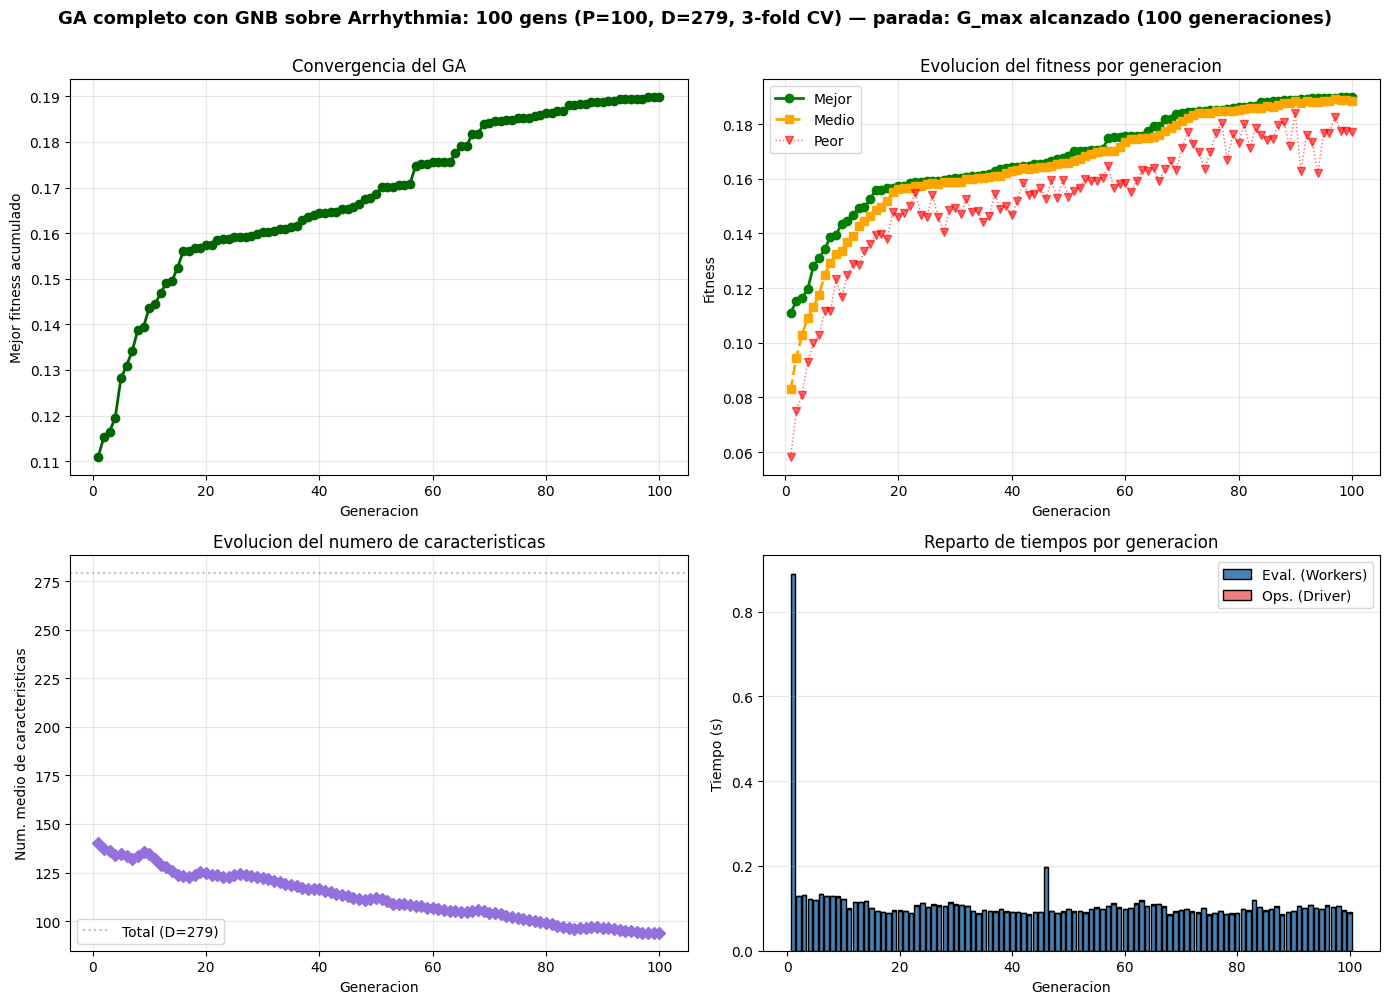

Grafico guardado en results/ga_full_arrhythmia_convergencia.png


In [20]:
import matplotlib.pyplot as plt

gens = list(range(1, gen_parada + 1))

# Mejor fitness acumulado (monotonamente creciente)
mejor_acum = []
actual = -float('inf')
for v in hist_mejor:
    actual = max(actual, v)
    mejor_acum.append(actual)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) Convergencia: mejor fitness acumulado
axes[0, 0].plot(gens, mejor_acum, 'o-', color='darkgreen', linewidth=2)
axes[0, 0].set_xlabel('Generacion')
axes[0, 0].set_ylabel('Mejor fitness acumulado')
axes[0, 0].set_title('Convergencia del GA')
axes[0, 0].grid(True, alpha=0.3)

# (2) Evolucion del fitness (mejor / medio / peor)
axes[0, 1].plot(gens, hist_mejor, 'o-', color='green', linewidth=2, label='Mejor')
axes[0, 1].plot(gens, hist_medio, 's--', color='orange', linewidth=2, label='Medio')
axes[0, 1].plot(gens, hist_peor,  'v:', color='red', linewidth=1, alpha=0.6, label='Peor')
axes[0, 1].set_xlabel('Generacion')
axes[0, 1].set_ylabel('Fitness')
axes[0, 1].set_title('Evolucion del fitness por generacion')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# (3) Num. medio de caracteristicas
axes[1, 0].plot(gens, hist_genes, 'D-', color='mediumpurple', linewidth=2)
axes[1, 0].axhline(y=D, color='gray', linestyle=':', alpha=0.5, label=f'Total (D={D})')
axes[1, 0].set_xlabel('Generacion')
axes[1, 0].set_ylabel('Num. medio de caracteristicas')
axes[1, 0].set_title('Evolucion del numero de caracteristicas')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# (4) Reparto de tiempos: evaluacion (Workers) vs operadores (Driver)
width = 0.8
axes[1, 1].bar(gens, t_eval_gen, width=width, color='steelblue',
               edgecolor='black', label='Eval. (Workers)')
axes[1, 1].bar(gens, t_ops_gen,  width=width, bottom=t_eval_gen,
               color='lightcoral', edgecolor='black', label='Ops. (Driver)')
axes[1, 1].set_xlabel('Generacion')
axes[1, 1].set_ylabel('Tiempo (s)')
axes[1, 1].set_title('Reparto de tiempos por generacion')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.suptitle(
    f'GA completo con GNB sobre Arrhythmia: {gen_parada} gens (P={P}, D={D}, {CV_FOLDS}-fold CV) — '
    f'parada: {motivo_parada}',
    fontsize=13, fontweight='bold', y=1.0
)
plt.tight_layout()
plt.savefig('../results/ga_full_arrhythmia_convergencia.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/ga_full_arrhythmia_convergencia.png")

---
## 8. Mejor Individuo Encontrado y Comparacion con Baseline

In [21]:
# Analisis del mejor individuo encontrado
indices_mejor = [i for i, gen in enumerate(mejor_global) if gen == 1]
nombres_mejor = [feature_names[i] for i in indices_mejor]

# Recalcular accuracy del mejor individuo (sin penalizacion)
gnb_final = GaussianNB()
scores_final = cross_val_score(gnb_final, X[:, indices_mejor], y, cv=CV_FOLDS, scoring='accuracy')

print("=" * 60)
print("MEJOR INDIVIDUO ENCONTRADO (Arrhythmia)")
print("=" * 60)
print(f"Fitness:  {mejor_fitness_global:.6f}")
print(f"Accuracy (CV5): {scores_final.mean():.6f} (+/- {scores_final.std():.6f})")
print(f"Caracteristicas: {len(indices_mejor)}/{D} ({len(indices_mejor)/D*100:.1f}%)")
print(f"\nCaracteristicas seleccionadas (primeras 40):")
for i, nombre in enumerate(nombres_mejor[:40]):
    print(f"  {i+1:>3d}. {nombre}")
if len(nombres_mejor) > 40:
    print(f"  ... y {len(nombres_mejor) - 40} mas")

print(f"\n{'=' * 60}")
print(f"COMPARACION CON BASELINE (todas las caracteristicas)")
print(f"{'=' * 60}")
gnb_base = GaussianNB()
scores_base = cross_val_score(gnb_base, X, y, cv=CV_FOLDS, scoring='accuracy')
fitness_base = ALPHA * scores_base.mean() - BETA * 1.0

print(f"Baseline accuracy (CV5): {scores_base.mean():.6f} (+/- {scores_base.std():.6f})")
print(f"Baseline fitness:        {fitness_base:.6f}")
print(f"Mejor GA fitness:        {mejor_fitness_global:.6f}")
print(f"Mejora en fitness:       {mejor_fitness_global - fitness_base:+.6f}")
print(f"Reduccion caracteristicas: {D} -> {len(indices_mejor)} ({(1 - len(indices_mejor)/D)*100:.1f}% menos)")
print("=" * 60)

MEJOR INDIVIDUO ENCONTRADO (Arrhythmia)
Fitness:  0.189779
Accuracy (CV5): 0.247903 (+/- 0.041415)
Caracteristicas: 93/279 (33.3%)

Caracteristicas seleccionadas (primeras 40):
    1. age
    2. sex
    3. Q-Tinterval
    4. Tinterval
    5. T
    6. QRST
    7. heartrate
    8. chDI_Qwave
    9. chDI_Rwave
   10. chDI_DD_RRwaveExists
   11. chDI_RPwaveExists
   12. chDI_RTwaveExists
   13. chDII_Swave
   14. chDII_RPwave
   15. chDII_intrinsicReflecttions
   16. chDII_RRwaveExists
   17. chDIII_Rwave
   18. chDIII_RRwaveExists
   19. chAVR_RRwaveExists
   20. chAVR_DD_RRwaveExists
   21. chAVR_DD_RPwaveExists
   22. chAVL_Rwave
   23. chAVL_SPwave
   24. chAVL_intrinsicReflecttions
   25. chAVL_DD_RRwaveExists
   26. chAVL_RTwaveExists
   27. chAVF_Qwave
   28. chAVF_Swave
   29. chAVF_intrinsicReflecttions
   30. chAVF_DD_RRwaveExists
   31. chAVF_RPwaveExists
   32. chV1_DD_RRwaveExists
   33. chV1_RTwaveExists
   34. chV2_SPwave
   35. chV2_DD_RRwaveExists
   36. chV2_RPwaveExists


---
## 9. Documentacion del Experimento (Hito 7)

Captura reproducible de la configuracion del experimento para el capitulo de evaluacion
experimental del TFM:

- **Configuracion de Spark** (master, cores, memoria, version)
- **Hardware** (OS, arquitectura, CPUs, versiones de librerias)
- **Parametros del GA** (tabla completa)
- **Resultados agregados** del run actual

Al final se exportan las series temporales del GA (fitness, caracteristicas, tiempos) a CSV
y un JSON con el resumen del experimento — estos artefactos pueden reutilizarse directamente
en el TFM y compararse con los de WDBC (notebook 04).

In [22]:
import platform
import json
import os
import csv
import sklearn
import pyspark

# --- Hardware ---
hw_info = {
    "os": platform.platform(),
    "machine": platform.machine(),
    "processor": platform.processor() or "apple silicon",
    "python_version": platform.python_version(),
    "cpu_count_logical": os.cpu_count(),
}

# --- Librerias ---
lib_info = {
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "pyspark": pyspark.__version__,
    "matplotlib": plt.matplotlib.__version__,
}

# --- Spark ---
spark_info = {
    "app_name": SPARK_APP_NAME,
    "master": SPARK_MASTER,
    "driver_memory": SPARK_DRIVER_MEM,
    "executor_memory": SPARK_EXECUTOR_MEM,
    "ui_port": SPARK_UI_PORT,
    "default_parallelism": NUM_CORES,
    "spark_version": spark.version,
    "app_id": sc.applicationId,
}

# --- Dataset ---
dataset_info = {
    "nombre": ds_info["nombre"],
    "fuente": ds_info["fuente"],
    "n_muestras": int(X.shape[0]),
    "n_caracteristicas": int(D),
    "n_clases": ds_info["n_clases"],
    "preprocesado": ds_info["preprocesado"],
}

# --- Parametros del GA ---
ga_params = {
    "P": P, "G_max": G_MAX, "D": D,
    "p_cross": P_CROSS, "p_mut": P_MUT, "p_mut_bit": P_MUT_BIT,
    "k_tourn": K_TOURN, "elite_size": ELITE_SIZE, "p_init": P_INIT,
    "eps_stop": EPS_STOP, "N_stop": N_STOP,
    "alpha": ALPHA, "beta": BETA, "cv_folds": CV_FOLDS,
    "seed": SEED,
}

# --- Resultados ---
mejor_cromosoma_py = [int(g) for g in mejor_global]

resultados = {
    "generaciones_ejecutadas": int(gen_parada),
    "motivo_parada": motivo_parada,
    "mejor_fitness": float(mejor_fitness_global),
    "mejor_n_caracteristicas": int(sum(mejor_cromosoma_py)),
    "mejor_cromosoma": mejor_cromosoma_py,
    "tiempo_total_s": round(float(t_total), 3),
    "tiempo_eval_total_s": round(float(sum(t_eval_gen)), 3),
    "tiempo_ops_total_s": round(float(sum(t_ops_gen)), 3),
    "tiempo_medio_gen_s": round(float(t_total) / int(gen_parada), 3),
}

print("=" * 64)
print("DOCUMENTACION DEL EXPERIMENTO (Hito 7) — Arrhythmia")
print("=" * 64)
print("\n--- Hardware ---")
for k, v in hw_info.items():
    print(f"  {k}: {v}")
print("\n--- Librerias ---")
for k, v in lib_info.items():
    print(f"  {k}: {v}")
print("\n--- Spark ---")
for k, v in spark_info.items():
    print(f"  {k}: {v}")
print("\n--- Dataset ---")
for k, v in dataset_info.items():
    print(f"  {k}: {v}")
print("\n--- Parametros del GA ---")
for k, v in ga_params.items():
    print(f"  {k}: {v}")
print("\n--- Resultados ---")
for k, v in resultados.items():
    if k in ("mejor_cromosoma",):
        continue
    print(f"  {k}: {v}")
print("=" * 64)

DOCUMENTACION DEL EXPERIMENTO (Hito 7) — Arrhythmia

--- Hardware ---
  os: macOS-26.5.1-arm64-arm-64bit
  machine: arm64
  processor: arm
  python_version: 3.9.6
  cpu_count_logical: 10

--- Librerias ---
  numpy: 1.24.3
  scikit-learn: 1.3.0
  pyspark: 3.5.0
  matplotlib: 3.7.1

--- Spark ---
  app_name: TFM_GA_Full_Arrhythmia
  master: local[*]
  driver_memory: 4g
  executor_memory: 4g
  ui_port: 4040
  default_parallelism: 8
  spark_version: 3.5.0
  app_id: local-1781348999894

--- Dataset ---
  nombre: Arrhythmia
  fuente: OpenML 'arrhythmia' v1
  n_muestras: 452
  n_caracteristicas: 279
  n_clases: 13
  preprocesado: imputacion por media (SimpleImputer)

--- Parametros del GA ---
  P: 100
  G_max: 100
  D: 279
  p_cross: 0.8
  p_mut: 0.2
  p_mut_bit: 0.0035842293906810036
  k_tourn: 5
  elite_size: 5
  p_init: 0.5
  eps_stop: 0.001
  N_stop: 15
  alpha: 0.9
  beta: 0.1
  cv_folds: 3
  seed: 42

--- Resultados ---
  generaciones_ejecutadas: 100
  motivo_parada: G_max alcanzado (10

In [23]:
# Exportacion de artefactos para el capitulo experimental del TFM
os.makedirs("../results", exist_ok=True)

PREFIX = "ga_full_arrhythmia"

# 1) Series temporales del GA -> CSV
csv_path = f"../results/{PREFIX}_series.csv"
with open(csv_path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow([
        "generacion", "mejor_fitness", "fitness_medio", "peor_fitness",
        "genes_medio", "t_eval_s", "t_ops_s"
    ])
    for i in range(gen_parada):
        w.writerow([
            i + 1,
            hist_mejor[i], hist_medio[i], hist_peor[i],
            hist_genes[i],
            t_eval_gen[i] if i < len(t_eval_gen) else 0.0,
            t_ops_gen[i]  if i < len(t_ops_gen)  else 0.0,
        ])
print(f"Series CSV: {csv_path}")

# 2) Resumen completo del experimento -> JSON
json_path = f"../results/{PREFIX}_experimento.json"
experimento = {
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "notebook": "05_ga_full_arrhythmia.ipynb",
    "hito": "Hito 6 + Hito 7 (extension a Arrhythmia)",
    "dataset": dataset_info,
    "hardware": hw_info,
    "librerias": lib_info,
    "spark": spark_info,
    "ga_params": ga_params,
    "resultados": resultados,
}
with open(json_path, "w") as f:
    json.dump(experimento, f, indent=2, ensure_ascii=False)
print(f"Resumen JSON: {json_path}")

# 3) Parametros del GA -> CSV (tabla reutilizable en el TFM)
params_csv = f"../results/{PREFIX}_parametros.csv"
with open(params_csv, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["parametro", "valor"])
    for k, v in ga_params.items():
        w.writerow([k, v])
print(f"Parametros CSV: {params_csv}")

print("\nArtefactos exportados correctamente para el capitulo experimental del TFM.")

Series CSV: ../results/ga_full_arrhythmia_series.csv
Resumen JSON: ../results/ga_full_arrhythmia_experimento.json
Parametros CSV: ../results/ga_full_arrhythmia_parametros.csv

Artefactos exportados correctamente para el capitulo experimental del TFM.


---
## 10. Limpieza de recursos

In [24]:
X_bc.destroy()
y_bc.destroy()
parar_spark(spark)

✓ Spark session detenida
